In [1]:
# ==========================================
# Block 1 - Import & Config
# ==========================================
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from scipy.optimize import minimize, differential_evolution
import matplotlib.pyplot as plt
from adjustText import adjust_text
import matplotlib.lines as mlines
from matplotlib.patches import Patch
import warnings
import random
warnings.filterwarnings('ignore')

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

ALPHA = 1e-4

In [2]:
# ==========================================
# Block 2 - Load Data
# ==========================================
# Load text accuracy data
text_df = pd.read_csv("eval_results/text_accuracy.csv", index_col=0)
# Load multimodal accuracy data
mm_df = pd.read_csv("eval_results/multimodal_accuracy.csv", index_col=0)

# Clean multimodal accuracy data
mm_df = mm_df.apply(
    lambda col: col.astype(str)
                   .str.replace('%', '', regex=False)
                   .replace('Error', np.nan)
                   .astype(float)
) / 100

# Standardize model naming
mm_df.index = mm_df.index.str.split('/').str[-1]

print("Text benchmark shape:", text_df.shape)
print("Multimodal benchmark shape:", mm_df.shape)

Text benchmark shape: (34, 40)
Multimodal benchmark shape: (34, 8)


In [3]:
# ==========================================
# Block 3 - Align Models & Define CKPT Info
# ==========================================
# Align models present in both datasets
common_models = sorted(set(text_df.index) & set(mm_df.index))
text_aligned = text_df.loc[common_models]
mm_aligned = mm_df.loc[common_models]

# Define available ckpts
ALL_CKPTS = [f'ckpt-{i}' for i in range(3000, 24001, 3000)]
ALL_CKPTS = [c for c in ALL_CKPTS if c in mm_aligned.columns]

TOKENS_PER_CKPT = 8192 * 512
D_all_np = np.array([int(c.split('-')[1]) for c in ALL_CKPTS], dtype=float) \
           * TOKENS_PER_CKPT / 1e9

print(f"Available ckpts ({len(ALL_CKPTS)}): {ALL_CKPTS}")
print(f"D_all_np: {D_all_np}")

Available ckpts (8): ['ckpt-3000', 'ckpt-6000', 'ckpt-9000', 'ckpt-12000', 'ckpt-15000', 'ckpt-18000', 'ckpt-21000', 'ckpt-24000']
D_all_np: [ 12.582912  25.165824  37.748736  50.331648  62.91456   75.497472
  88.080384 100.663296]


In [4]:
# ==========================================
# Block 4 - Split Train / Holdout
# ==========================================
HOLDOUT_MODELS = ['Qwen2.5-72B-Instruct', 'Qwen2.5-72B']
train_models = [m for m in common_models if m not in HOLDOUT_MODELS]

# Training set trajectory matrix
L_train_np = mm_aligned.loc[train_models, ALL_CKPTS].values.astype(float)

# Start point: ckpt-3000
L_start_np = L_train_np[:, 0]
D_start = D_all_np[0]

print(f"Train models: {len(train_models)}")
print(f"L_train_np shape: {L_train_np.shape}")
print(f"Start ckpt: {ALL_CKPTS[0]}, D_start={D_start:.4f}")
print(f"NaN count: {np.isnan(L_train_np).sum()}")

Train models: 32
L_train_np shape: (32, 8)
Start ckpt: ckpt-3000, D_start=12.5829
NaN count: 0


In [5]:
# ==========================================
# Block 5 - PCA on Text Benchmark
# ==========================================
benchmark_en = list(text_aligned.columns)  # all benchmarks
X_train = text_aligned.loc[train_models, benchmark_en].values

max_pc = min(len(train_models) - 1, len(benchmark_en))
pca = PCA(n_components=max_pc)
X_pca = pca.fit_transform(X_train)

cumvar = np.cumsum(pca.explained_variance_ratio_)
n_pc = int(np.argmax(cumvar >= 0.95)) + 1
n_pc = max(1, min(n_pc, max_pc))
X_pca = X_pca[:, :n_pc]

S_list = [X_pca[:, i] for i in range(n_pc)]

print(f"PCA n_pc = {n_pc} (95% variance retained)")
print(f"X_pca shape: {X_pca.shape}")

PCA n_pc = 12 (95% variance retained)
X_pca shape: (32, 12)


In [6]:
# ==========================================
# Block 6 - Core Functions
# ==========================================
def huber_loss(x, delta=1.0):
    abs_x = np.abs(x)
    return np.where(abs_x <= delta, 0.5 * x**2, delta * (abs_x - 0.5 * delta))

def fit_start(params, S_list, L_start):
    A, P0 = params[:2]
    k_coeffs = params[2:]
    S = sum(k * s_data for k, s_data in zip(k_coeffs, S_list))
    L_pred = A * S + P0
    residual = L_pred - L_start
    return np.sum(huber_loss(residual)) + ALPHA * np.sum(k_coeffs ** 2)

def run_opt_start(S_list, L_start, n_pc, seed=RANDOM_SEED):
    args_data = (S_list, L_start)
    bounds_de = [(0, 10.0), (-1.0, 1.0)] + [(-50.0, 50.0)] * n_pc
    global_res = differential_evolution(
        fit_start, bounds=bounds_de, args=args_data,
        strategy='best1bin', maxiter=2000, popsize=8,
        workers=-1, seed=seed, disp=False
    )
    bounds_local = [(0, None), (None, None)] + [(None, None)] * n_pc
    final_res = minimize(
        fit_start, x0=global_res.x, args=args_data,
        method='L-BFGS-B', bounds=bounds_local,
        options={'maxiter': 1000000, 'maxfun': 1000000, 'disp': False}
    )
    return final_res

In [7]:
# ==========================================
# Block 7 - Run Start Point Fitting
# ==========================================
res_start = run_opt_start(S_list, L_start_np, n_pc)
A_start, P0_start = res_start.x[:2]
k_start = res_start.x[2:]

print(f"Optimization status: {res_start.message}")

# Compute S for training models
S_train = sum(k * s_data for k, s_data in zip(k_start, S_list))

# Predict start point
L_start_pred = A_start * S_train + P0_start

# MAE
mae_start = np.mean(np.abs(L_start_pred - L_start_np))
print(f"Start point MAE: {mae_start*100:.4f}%")

Optimization status: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Start point MAE: 1.2208%


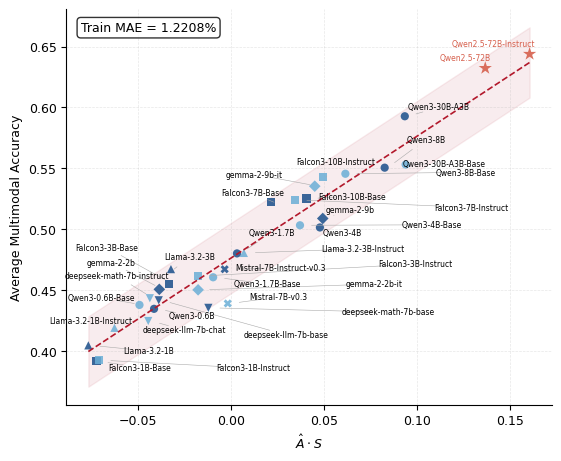

In [9]:
# ==========================================
# Block 8 - Plot Start Point Validation
# ==========================================
FIG_HEIGHT  = 4.5
FIG_WIDTH   = 5.5

FONT_SIZE_LABEL   = 9       # Axis label font size
FONT_SIZE_TICK    = 9       # Tick label font size
FONT_SIZE_TEXT    = 5.5       # Model name annotation font size
FONT_SIZE_LEGEND  = 6.5       # Legend font size
FONT_SIZE_MAE     = 9       # MAE annotation font size

MARKER_SIZE_SCATTER_TRAIN   = 35    # Train scatter marker size
MARKER_SIZE_SCATTER_HOLDOUT = 100   # Holdout scatter marker size
MARKER_SIZE_LEGEND          = 5     # Legend marker size

LINE_WIDTH_FIT      = 1.2   # Fitted scaling law line width
LINE_WIDTH_GRID     = 0.5   # Grid line width

ARROW_LINE_WIDTH    = 0.4   # adjust_text arrow line width

MARKER_MAP = {
    'Qwen3'    : 'o',
    'Falcon3'  : 's',
    'LLaMA-3.2': '^',
    'Gemma-2'  : 'D',
    'DeepSeek' : 'v',
    'Mistral'  : 'X',
    'Qwen2.5'  : '*',
}

COLOR_MAP = {
    'chat': '#1a4f8a',
    'base': '#6aaed6',
    'holdout_true' : '#D6604D',
}

n_train = len(train_models)
model_names = train_models

families = []
for name in train_models:
    if 'qwen3' in name.lower():
        families.append('Qwen3')
    elif 'falcon3' in name.lower():
        families.append('Falcon3')
    elif 'llama' in name.lower():
        families.append('LLaMA-3.2')
    elif 'gemma' in name.lower():
        families.append('Gemma-2')
    elif 'deepseek' in name.lower():
        families.append('DeepSeek')
    elif 'mistral' in name.lower():
        families.append('Mistral')
    else:
        families.append('Other')

model_types = ['chat' if m_idx % 2 == 0 else 'base' for m_idx in range(n_train)]
unique_families = list(dict.fromkeys(families)) + ['Qwen2.5']

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT), constrained_layout=True)

AS_values = A_start * S_train
valid     = ~np.isnan(L_start_np)

X_holdout_72b = text_aligned.loc[HOLDOUT_MODELS, text_aligned.columns].values
X_pca_72b     = pca.transform(X_holdout_72b)[:, :n_pc]

S_72b = np.zeros(len(HOLDOUT_MODELS), dtype=float)
for k, s_data in zip(k_start, [X_pca_72b[:, i] for i in range(n_pc)]):
    S_72b += k * s_data

AS_72b       = A_start * S_72b
L_72b_pred   = AS_72b + P0_start
L_72b_true   = mm_aligned.loc[HOLDOUT_MODELS, ALL_CKPTS].values[:, 0].astype(float)

texts         = []
all_scatter_x = []
all_scatter_y = []

for m_idx in range(n_train):
    if not valid[m_idx]:
        continue

    fam    = families[m_idx]
    mtype  = model_types[m_idx]
    marker = MARKER_MAP[fam]
    color  = COLOR_MAP[mtype]

    ax.scatter(AS_values[m_idx], L_start_np[m_idx],
               marker=marker, color=color,
               s=MARKER_SIZE_SCATTER_TRAIN, alpha=0.85,
               edgecolors='none', zorder=3)

    all_scatter_x.append(AS_values[m_idx])
    all_scatter_y.append(L_start_np[m_idx])

    t = ax.text(
        AS_values[m_idx] + (AS_values[valid].max() - AS_values[valid].min()) * 0.01,
        L_start_np[m_idx],
        model_names[m_idx],
        fontsize=FONT_SIZE_TEXT, color='black',
        va='bottom', ha='left', zorder=5,
    )
    texts.append(t)

x_min  = min(AS_values[valid].min(), AS_72b.min())
x_max  = max(AS_values[valid].max(), AS_72b.max())
x_line = np.linspace(x_min, x_max, 200)
y_line = x_line + P0_start

ax.plot(x_line, y_line,
        color='#B2182B', linewidth=LINE_WIDTH_FIT, linestyle='--', zorder=4)

residuals = L_start_pred - L_start_np
std_train = np.std(residuals)
ax.fill_between(
    x_line,
    y_line - 1.96 * std_train,
    y_line + 1.96 * std_train,
    color='#B2182B', alpha=0.08, zorder=1,
)

for i, model in enumerate(HOLDOUT_MODELS):
    marker = MARKER_MAP['Qwen2.5']
    ax.scatter(AS_72b[i], L_72b_true[i],
               marker=marker,
               color=COLOR_MAP['holdout_true'],
               s=MARKER_SIZE_SCATTER_HOLDOUT, alpha=0.9,
               edgecolors='none', zorder=6)
    # Default offset (right side)
    x_offset, y_offset = 4, 4
    ha_align = 'left'

    # Move both Qwen2.5-72B and Qwen2.5-72B-Instruct to the left
    if model in ["Qwen2.5-72B", "Qwen2.5-72B-Instruct"]:
        x_offset = 4
        ha_align = 'right'

    ax.annotate(model,
                xy=(AS_72b[i], L_72b_true[i]),
                xytext=(x_offset, y_offset),
                textcoords='offset points',
                fontsize=FONT_SIZE_TEXT, color=COLOR_MAP['holdout_true'],
                va='bottom', ha=ha_align, zorder=7)

shape_handles = [
    mlines.Line2D([], [], color='#555555',
                  marker=MARKER_MAP[fam], linestyle='None',
                  markersize=MARKER_SIZE_LEGEND, label=fam)
    for fam in unique_families
]
color_handles = [
    mlines.Line2D([], [], color=COLOR_MAP['chat'],
                  marker='o', linestyle='None',
                  markersize=MARKER_SIZE_LEGEND, label='Train Instruct'),
    mlines.Line2D([], [], color=COLOR_MAP['base'],
                  marker='o', linestyle='None',
                  markersize=MARKER_SIZE_LEGEND, label='Train Base'),
    mlines.Line2D([], [], color=COLOR_MAP['holdout_true'],
                  marker='o', linestyle='None',
                  markersize=MARKER_SIZE_LEGEND, label='Holdout'),
]
fit_handle = mlines.Line2D(
    [], [], color='#B2182B', linewidth=LINE_WIDTH_FIT,
    linestyle='--', label='Fitted Scaling Law'
)
interval_handle = Patch(
    facecolor='#B2182B', alpha=0.2, edgecolor='none',
    label=f'Prediction Error Band (±1.96σ)'
)
separator = Patch(color='none', label='')

adjust_text(
    texts,
    x=all_scatter_x,
    y=all_scatter_y,
    ax=ax,
    expand=(1.5, 1.5),
    arrowprops=dict(
        arrowstyle='-',
        color='#aaaaaa',
        lw=ARROW_LINE_WIDTH,
        shrinkA=12,
        shrinkB=6,
    ),
    force_text=(0.4, 0.4),  
    force_points=(2.2, 2.5), 
    force_static=(0.2, 0.2), 
    iter_lim=3500 
)

ax.text(0.03, 0.97,
        f'Train MAE = {mae_start*100:.4f}%',
        transform=ax.transAxes, fontsize=FONT_SIZE_MAE,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel(r'$\hat{A} \cdot S$', fontsize=FONT_SIZE_LABEL)
ax.set_ylabel('Average Multimodal Accuracy', fontsize=FONT_SIZE_LABEL)
ax.tick_params(labelsize=FONT_SIZE_TICK)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.3, linewidth=LINE_WIDTH_GRID)

plt.show()